In [10]:
import os
import numpy as np 
from math import gcd 
import json
import matplotlib.pyplot as  plt

In [3]:
rng = np.random.default_rng(580) # the scope range considering y or x = -256 <-> 256
OUTPUT = "../../data/GeneratedData" # where we will store the generated data 
os.makedirs(OUTPUT, exist_ok=True)
TARGET = 150 # this will be the amount of data generated per category 

In [4]:
def normalize_stokes(strokes):
    pts = np.vstack(strokes)
    lo, hi = pts.min(0), pts.max(0)
    center = (lo +  hi) / 2 
    scale = (hi-lo).max() / 2 or 1.0
    return [((s- center)/ scale * 0.9).round(4).tolist() for s in strokes ]
#this function will ensure all our strokes are centered  and fit inbetween -0.9 and 0.9 

In [5]:
def fingerprint(strokes):
    pts = np.vstack([np.array(s) for s in strokes])
    sub = np.round(pts[:: max(1, len(pts) //40)], 2)
    return hash(sub.tobytes())


In [6]:
def collect(make, target=TARGET, tries=20000):
    out, seen  = [], set()
    for _ in range(tries):
        if len(out) >= target:
            break
        strokes, params = make()
        s =  normalize_stokes(strokes)
        fp = fingerprint(s)
        if fp in seen:
            continue
        seen.add(fp)
        out.append({"params": params, "strokes": s})
    return out

def save(name, items):
    with open(f"{OUTPUT}/{name}.json", "w")  as f :
        json.dump(items, f)
    print(f"{name}:   {len(items)} samples") 


In [7]:
def lissajous(a, b, phi, delta, n=600):
    t = np.linspace(0, 2 * np.pi, n)
    return np.column_stack([np.sin(a * t + phi), np.sin(b * t + delta)])


def make_lissajous():
    a, b = (int(v) for v in rng.integers(1, 9, 2))
    phi = rng.uniform(0, 2*np.pi)
    delta = rng.uniform(0, 2 *np.pi)
    return [lissajous(a, b, phi, delta)], {"a": a, "b": b, "phi": round(phi, 3), "delta": round(delta, 3)}

lissajous_data = collect(make_lissajous)


In [9]:
def make_rose(): 
    p, q = (int(v) for v in rng.integers(1, 10, 2 ))
    k = p / q 
    c = float(rng.choice([0.0, 0.3, 0.5]))
    m = int(rng.integers(2, 7))
    th = np.linspace(0, 2 * np.pi * q, 1200)
    r = np.cos(k * th) + c *np.cos(m * th)
    stroke = np.column_stack([r * np.cos(th), r * np.sin(th)])
    return [stroke], {"p": p, "q": q, "c": c, "m": m}


rose_data = collect(make_rose)

In [11]:
def hypotrochoid(R, r, d , n=2000):
    g = gcd(R, r)
    T = 2 * np.pi * (r // g)
    t = np.linspace(0, T, n)
    k = (R-r) / r
    x = (R - r) * np.cos(t) + d * np.cos(k * t)
    y = (R - r) * np.sin(t) - d * np.sin(k * t)  
    return np.column_stack([x, y])

def make_spiro():
    R = int(rng.integers(3, 25))
    r = int(rng.integers(1, R))
    d = round(float(rng.uniform(0.2, 1.0)) * r, 3)
    return [hypotrochoid(R, r, d)], {"R": R, "r": r, "d": d}

spiro_data = collect(make_spiro)

In [13]:
def random_arc_wedge(W, n_pts=40):
    u = np.linspace(0, 1, n_pts)
    theta = W * u 
    r = np.full_like(u, 0.3)
    for j in range(1, 4):
        r += rng.uniform(-0.15, 0.15) * np.sin(np.pi * j * u + rng.uniform(0, 2 * np.pi))
    r = np.clip(r, 0.05, 1.0)
    return np.column_stack([r * np.cos(theta), r * np.sin(theta)])

def kaleido(n, mirror, arcs):
    strokes = []
    for k in range(n):
        for pts in arcs:
            r = np.hypot(pts[:, 0], pts[:, 1])
            th = np.arctan2(pts[:, 1], pts[:, 0])
            ang = th + 2 * np.pi * k/ n
            strokes.append(np.column_stack([r * np.cos(ang), r * np.sin(ang)]))
            if mirror:
                ang2 = -th + 2  * np.pi * k / n
                strokes.append(np.column_stack([r * np.cos(ang2), r * np.sin(ang)]))
    return strokes


def make_kaleidoscope():
    n = int(rng.choice([3, 4, 5, 6, 7, 8, 10, 12]))
    mirror = bool(rng.random() < 0.7)
    W = 2 * np.pi / n
    arcs = [random_arc_wedge(W) for _ in range(rng.integers(1, 3))]
    return kaleido(n, mirror, arcs), {"Folds": n, "mirror": mirror, "arcs": len(arcs)}


kaleido_data = collect(make_kaleidoscope)

In [14]:
def truchet(g, tile=1.0, n_pts=12):
    strokes = []
    for i in range(g):
        for j in range(g):
            flip = rng.random() < 0.5
            x0, y0 = i * tile, j * tile
            if flip:
               centers = [(x0, y0), (x0 + tile, y0 + tile)]
            else:
                centers = [(x0 + tile, y0), (x0, y0 + tile)]
            for cx, cy in centers:
                base = np.arctan2(y0 + tile /2 - cy, x0 + tile / 2 - cx)
                a = np.linspace(base - np.pi / 4, base + np.pi / 4, n_pts)
                strokes.append(np.column_stack([cx + tile / 2 * np.cos(a), cy + tile / 2 * np.sin(a)]))

    return strokes


def make_truchet():
    g = int(rng.integers(3, 11))
    return truchet(g, n_pts=int(rng.integers(8, 21))), {"grid": g}

truchet_data = collect(make_truchet)

In [15]:
datasets =  {
    "lissajous": lissajous_data,
    "rose": rose_data,
    "spiro": spiro_data,
    "kaleidoscope": kaleido_data,
    "truchet": truchet_data,
}

for name, data in datasets.items():
    save(name, data)

lissajous:   150 samples
rose:   150 samples
spiro:   150 samples
kaleidoscope:   150 samples
truchet:   150 samples


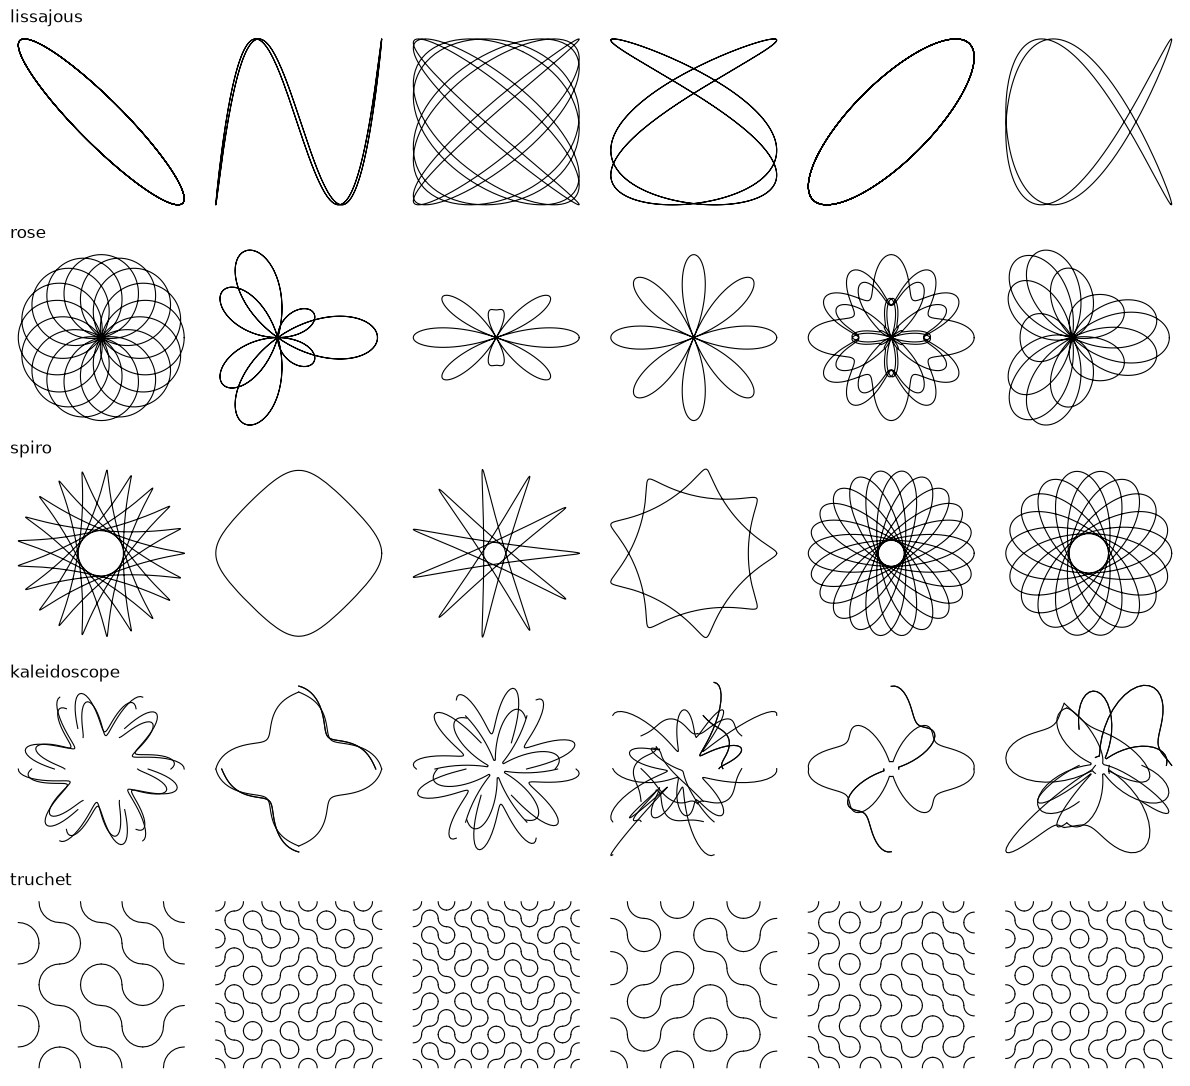

In [21]:
fig, axes = plt.subplots(len(datasets), 6, figsize=(12, 2.2 * len(datasets)))
for row, (name, data) in enumerate(datasets.items()):
    for ax in axes[row]:
        item = data[rng.integers(len(data))]
        for s in item["strokes"]:
            s = np.array(s)
            ax.plot(s[:, 0], s[:, 1], color="black", lw=0.8)
        ax.set_aspect("equal")
        ax.axis("off")
    axes[row][0].set_title(name, fontsize=12, loc="left", pad=6)
plt.tight_layout()
plt.show()